# Module 6 · Session 1 (Syllabus Session 26)
## Quantum, neuromorphic and alternative computing paradigms
**BCSAI · IE University · Oscar Diez · 2026–27**

Which architecture fits the problem? We investigate five small examples before making hardware choices.

**Learning objectives**
1. Explain event-driven processing, neuron state and the importance of sparsity.
2. Relate a matrix–vector operation to in-memory and photonic computing.
3. Explain quantum interference and the limits of measurement and simulation.
4. Evaluate a hybrid workflow using the complete cost, including transfer and setup.
5. Separate executed CPU evidence, operation counts, illustrative models and untested hardware claims.

**Method:** Real problem → Prediction → Code → Run → Result → Explanation → Student experiment → Takeaway.

**Class route:** E1 sparse events, E2 neuron state, E3 matrix arithmetic, E4 interference, E5 hybrid costs. The slide session takes 80 minutes; finish the parameter investigations afterwards.

**Evidence boundary:** E1–E4 execute real C code on a CPU to simulate concepts. E1 counts useful weighted updates, not elapsed time or joules. E3 quantization is an error model, not a photonic/resistive device model. E4 simulates a single ideal qubit, not a QPU or quantum speedup. E5 computes an illustrative cost model. No accelerator hardware is required or measured.

**Validation at publication:** the author executed the notebook code cells locally. SciTech execution is **NOT RUN** pending an actual student/instructor cluster run. Saved local outputs include their host and execution context. Always rerun to obtain your own results.


## 0 · SciTech access and execution
Use the existing SciTech JupyterHub and a Python 3 kernel. Save a personal copy in a directory you own. Open this notebook using **File → Open from URL**, then run cells in order.

For a terminal outside campus:
```bash
ssh -J <username>@ssh.iesci.tech <username>@10.205.20.10
hostname
sinfo
```
The login node is `rust`. Do not SSH directly to compute nodes. See the repository's [cluster guide](https://github.com/OscarDiez/hpc_course/blob/main/cluster/README.md).

The notebook writes exact embedded C, runner and batch files into `m6s1_lab/`. It needs Python 3.9+ and GCC with C11 support. It installs nothing and downloads nothing. The Python kernel orchestrates the experiments; the core calculations use C.

- On SciTech, the default **slurm** route submits a separate one-node, one-task, one-CPU, 1 GB, two-minute CPU allocation. Queue time is additional.
- Off-cluster, the default **local** route runs tiny correctness simulations. These are not performance benchmarks.
- Submission and collection are separate. A queued job prints **NOT RUN** until results are available. Rerun the collection cell after completion.
- **PASS** means checks passed, **FAIL** means an attempted operation/check failed, **SKIPPED** means a required feature was unavailable or outside scope, and **NOT RUN** means execution has not happened or has not completed.
- MPI and GPU execution are SKIPPED by design. Optional OpenMP checks correctness only. If enabled, request two CPUs with `CPUS=2`.

If GCC is absent, use the site's compiler environment. Existing course jobs use `module load foss/2023b`, but module availability can differ in batch shells. The job uses that module when exposed and otherwise inspects inherited GCC. No missing feature counts as PASS.


In [1]:
import os, sys, json, math, hashlib, platform, shutil, subprocess, time, random
from pathlib import Path
ROOT = Path("m6s1_lab").resolve()
ROOT.mkdir(exist_ok=True)
print("Host:", platform.node())
print("Python:", sys.version.split()[0])
print("GCC:", shutil.which("gcc"))
print("Slurm:", shutil.which("sbatch"))
print("Working directory:", ROOT)
print("Current kernel allocation:", os.environ.get("SLURM_JOB_ID", "none"))
# The compute job has its own allocation; seeing CPUs here does not allocate them.
answers = {}
def feedback(number, correct, explanation):
    answer = answers.get(number)
    if answer is None:
        print(f"Q{number}: choose A, B, C or D first.")
    elif str(answer).upper() not in ("A","B","C","D"):
        print("Use a single letter A–D.")
    else:
        print("Correct" if str(answer).upper()==correct else "Review your prediction")
        print(explanation)


Host: a9e396123eda
Python: 3.12.14
GCC: /usr/bin/gcc
Slurm: None
Working directory: /workspace/scratch/203ecc1de7e8/notebook_validation/m6s1_lab
Current kernel allocation: none


### Settings: change one parameter at a time
The suite always includes baseline comparison cases. Your chosen value adds a row when it differs.

| Setting | Meaning | First change |
|---|---|---|
| `event_period` | One input change every this many frames | 50 to 100 |
| `threshold` | Firing threshold in the discrete neuron model | 1.0 to 1.3 |
| `bits` | Weight quantization resolution | 3 to 8 |
| `phase` | Relative phase between two Hadamard gates, radians | 0 to π |
| `overhead_ms` | Assumed transfer/setup cost in a hybrid model | 5 to 80 |

After a change, rerun from this settings cell. A fingerprint includes all source files, settings, execution route and CPU request. A completed identical run can be reused. Set `REPEAT=True` for an intentional repeat. Different runs use separate directories so results cannot silently mix.


In [2]:
SETTINGS = {"event_period": 50, "threshold": 1.0, "bits": 3,
            "phase": 0.0, "overhead_ms": 5.0, "openmp": False}
EXECUTION = "slurm" if shutil.which("sbatch") else "local"
CPUS = 1  # set to 2 only for the optional OpenMP correctness check
REPEAT = False
print("Requested route:", EXECUTION, "settings:", SETTINGS)


Requested route: local settings: {'event_period': 50, 'threshold': 1.0, 'bits': 3, 'phase': 0.0, 'overhead_ms': 5.0, 'openmp': False}


### Inspect the actual code
The next cell holds the complete source files. Expand it and locate `events`, `lif`, `matvec` and `quantum` in the C source. Each prints a `RESULT` record. `run_suite.py` compares the outputs with independent Python calculations and records provenance.

The files are embedded so the raw notebook works without a repository checkout. Their bytes match `session_demos/26_alternative_paradigms/` at publication.


In [3]:
SOURCES = {}
SOURCES['m6s1_lab.c'] = r'''/* M6S1: small CPU concept simulations, never accelerator benchmarks. */
#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <math.h>
#include <complex.h>
#ifdef _OPENMP
#include <omp.h>
#endif

static void require(int ok, const char *name) {
    if (!ok) { fprintf(stderr,"FAIL: %s\n",name); exit(3); }
    printf("PASS: %s\n",name);
}
static double number(const char *s, double low, double high) {
    char *end; double x=strtod(s,&end);
    if (end==s || *end || !isfinite(x) || x<low || x>high) {
        fprintf(stderr,"FAIL: parameter must be in [%g,%g]\n",low,high); exit(2);
    }
    return x;
}
static int integer(const char *s,int low,int high) {
    double x=number(s,low,high);
    if (x!=floor(x)) { fprintf(stderr,"FAIL: expected integer\n"); exit(2); }
    return (int)x;
}

/* Compare two equivalent linear sensor aggregators. Sparse events are provided
   to the second algorithm. Constructing events from dense frames has a cost
   outside this operation-count model. A CPU can also exploit event streams. */
static void events(int period) {
    const int frames=1000, channels=16;
    double x[16]={0}, y=0, dense_total=0, event_total=0;
    int count=0, all_equal=1;
    for (int t=0;t<frames;t++) {
        if (t%period==0) {
            int c=count%channels;
            double delta=(double)((count%3)+1);
            x[c]+=delta;
            y+=(c+1)*delta; /* Update only the changed channel. */
            count++;
        }
        double reference=0;
        for (int c=0;c<channels;c++) reference+=(c+1)*x[c];
        if (fabs(y-reference)>=1e-12) all_equal=0;
        dense_total+=reference; event_total+=y;
    }
    require(all_equal,"all_event_steps_equal");
    require(dense_total==event_total,"event_checksums_equal");
    printf("RESULT events period=%d frames=%d channels=%d events=%d dense_updates=%d event_updates=%d checksum=%.0f\n",
           period,frames,channels,count,frames*channels,count,event_total);
}

/* Discrete leaky integrate-and-fire teaching model. No training rule. */
static void lif(double threshold) {
    const double decay=0.8, input=0.3;
    double v=0; int spikes=0;
    printf("TRACE step before_reset spike after_reset\n");
    for (int t=0;t<12;t++) {
        double before=decay*v+input;
        int spike=before>=threshold;
        v=spike ? 0 : before;
        spikes+=spike;
        require(v>=0 && (v<threshold || !spike),"lif_state_valid");
        printf("TRACE %d %.9f %d %.9f\n",t,before,spike,v);
    }
    printf("RESULT lif threshold=%.9f spikes=%d final_v=%.9f\n",threshold,spikes,v);
}

/* Same y=W*x mathematics may map to digital, resistive or photonic hardware.
   Quantizing weights is a simplified error model, not a device simulator. */
static void matvec(int bits) {
    double y[4]={0}, q[4]={0}, max_error=0;
    const double levels=(double)((1u<<bits)-1u);
#ifdef _OPENMP
    #pragma omp parallel for schedule(static)
#endif
    for (int i=0;i<4;i++) {
        for (int j=0;j<4;j++) {
            double w=(double)((i+1)*(j+1))/17.0;
            double x=(double)(j+1)/10.0;
            y[i]+=w*x;
            q[i]+=(round(w*levels)/levels)*x;
        }
    }
    printf("MATRIX row reference quantized abs_error\n");
    for (int i=0;i<4;i++) {
        double err=fabs(q[i]-y[i]);
        require(fabs(y[i]-(i+1)*3.0/17.0)<1e-12,"matvec_reference");
        /* Each quantized weight differs by at most half one level. */
        require(err<=0.5/levels+1e-12,"matvec_quantization_bound");
        if (err>max_error) max_error=err;
        printf("MATRIX %d %.12f %.12f %.12f\n",i,y[i],q[i],err);
    }
    printf("RESULT matvec bits=%d max_error=%.12f\n",bits,max_error);
}

/* Exact one-qubit state-vector simulation: H, phase(phi), H. */
static void quantum(double phi) {
    double complex a=1/sqrt(2.0), b=1/sqrt(2.0);
    b*=cexp(I*phi);
    double complex out0=(a+b)/sqrt(2.0), out1=(a-b)/sqrt(2.0);
    double p0=pow(cabs(out0),2), p1=pow(cabs(out1),2);
    require(fabs(p0+p1-1)<1e-12,"quantum_normalization");
    require(fabs(p1-pow(sin(phi/2),2))<1e-12,"quantum_analytic_probability");
    printf("RESULT quantum phi=%.12f p0=%.12f p1=%.12f\n",phi,p0,p1);
}

int main(int argc,char **argv) {
    if (argc!=3) {
        fprintf(stderr,"Usage: m6s1_lab events PERIOD | lif THRESHOLD | matvec BITS | quantum PHASE\n");
        return 2;
    }
    if (!strcmp(argv[1],"events")) events(integer(argv[2],1,1000));
    else if (!strcmp(argv[1],"lif")) lif(number(argv[2],0.1,2));
    else if (!strcmp(argv[1],"matvec")) matvec(integer(argv[2],2,12));
    else if (!strcmp(argv[1],"quantum")) quantum(number(argv[2],0,6.283185307179587));
    else { fprintf(stderr,"FAIL: unknown experiment\n"); return 2; }
    return 0;
}
'''
SOURCES['run_suite.py'] = r'''#!/usr/bin/env python3
"""Run tiny C concept simulations and independently check the results."""
import argparse
import hashlib
import json
import math
import os
from pathlib import Path
import platform
import shutil
import subprocess
import sys

DEFAULTS = {"event_period": 50, "threshold": 1.0, "bits": 3,
            "phase": 0.0, "overhead_ms": 5.0, "openmp": False}

def validate(s):
    assert set(s) == set(DEFAULTS), "Use the documented settings only"
    for key, lo, hi in [("event_period",1,1000),("bits",2,12)]:
        assert type(s[key]) is int and lo <= s[key] <= hi, key
    for key, lo, hi in [("threshold",0.1,2),("phase",0,2*math.pi),
                        ("overhead_ms",0,1000)]:
        assert type(s[key]) in (int,float) and math.isfinite(s[key]) and lo <= s[key] <= hi, key
    assert type(s["openmp"]) is bool

def command(args, cwd, env=None):
    p = subprocess.run([str(a) for a in args],cwd=cwd,env=env,text=True,
                       capture_output=True,timeout=20)
    if p.returncode:
        raise RuntimeError(f"Command failed ({p.returncode}): {args}\n{p.stdout}\n{p.stderr}")
    return p.stdout

def record(text):
    line = next(x for x in text.splitlines() if x.startswith("RESULT "))
    return {k: float(v) for k,v in (part.split("=",1) for part in line.split()[2:])}

def main(folder, settings):
    validate(settings)
    folder=Path(folder).resolve()
    source=folder/"m6s1_lab.c"
    result={"settings":settings,"source_sha256":hashlib.sha256(source.read_bytes()).hexdigest(),
            "provenance":{"host":platform.node(),"platform":platform.platform(),
             "python":sys.version.split()[0],"slurm_job_id":os.environ.get("SLURM_JOB_ID"),
             "context":"SLURM_CPU" if os.environ.get("SLURM_JOB_ID") else "LOCAL_CPU",
             "flags":"-O2 -std=c11 -Wall -Wextra -Werror -lm"},
            "experiments":{}, "optional":{}, "raw":{}}
    cc=shutil.which("gcc")
    if not cc:
        for name in ("E1","E2","E3","E4"):
            result["experiments"][name]={"status":"SKIPPED","reason":"gcc unavailable. Use site compiler instructions."}
    else:
        result["provenance"]["compiler"]=command([cc,"--version"],folder).splitlines()[0]
        try:
            command([cc,"-O2","-std=c11","-Wall","-Wextra","-Werror",source,"-lm","-o",folder/"m6s1_lab"],folder)
        except Exception as exc:
            for name in ("E1","E2","E3","E4"):
                result["experiments"][name]={"status":"FAIL","reason":str(exc)}
        else:
            for name, mode, values in [
                ("E1","events",[50,100,settings["event_period"]]),
                ("E2","lif",[1.0,1.3,settings["threshold"]]),
                ("E3","matvec",[3,8,settings["bits"]]),
                ("E4","quantum",[0,math.pi/2,math.pi,settings["phase"]])]:
                rows=[]
                try:
                    for value in dict.fromkeys(values):
                        text=command([folder/"m6s1_lab",mode,value],folder)
                        row=record(text)
                        result["raw"][f"{mode}:{value}"]=text
                        if name=="E1":
                            x=[0]*16; expected=0; count=0
                            for t in range(1000):
                                if t%value==0:
                                    x[count%16] += count%3+1
                                    count+=1
                                expected+=sum((i+1)*v for i,v in enumerate(x))
                            assert row["checksum"]==expected and row["events"]==count
                            assert row["event_updates"]==count and row["dense_updates"]==16000
                        elif name=="E2":
                            v=0; spikes=0
                            for _ in range(12):
                                v=.8*v+.3
                                if v>=value: v=0; spikes+=1
                            assert row["spikes"]==spikes and abs(row["final_v"]-v)<1e-8
                        elif name=="E3":
                            levels=2**value-1
                            errors=[]
                            for i in range(4):
                                approximate=sum((math.floor((i+1)*(j+1)/17*levels+.5)/levels)*(j+1)/10 for j in range(4))
                                errors.append(abs(approximate-(i+1)*3/17))
                            assert abs(row["max_error"]-max(errors))<1e-10
                        else:
                            assert abs(row["p1"]-math.sin(value/2)**2)<1e-10
                            assert abs(row["p0"]+row["p1"]-1)<1e-10
                        rows.append(row)
                    result["experiments"][name]={"status":"PASS","evidence":"CPU_SIMULATION","rows":rows}
                except Exception as exc:
                    result["experiments"][name]={"status":"FAIL","reason":str(exc),"rows":rows}
        result["optional"]["OpenMP"]={"status":"NOT RUN","reason":"Set openmp=True and provide two allocated CPUs to request this optional check."}
        if settings["openmp"] and all(result["experiments"][k]["status"]=="PASS" for k in ("E1","E2","E3","E4")):
            allocated=int(os.environ.get("SLURM_CPUS_PER_TASK","1"))
            if os.environ.get("SLURM_JOB_ID") and allocated<2:
                result["optional"]["OpenMP"]={"status":"SKIPPED","reason":"Need two CPUs. Request --cpus-per-task=2."}
            else:
                p=subprocess.run([cc,"-O2","-std=c11","-Wall","-Wextra","-Werror","-fopenmp",str(source),"-lm","-o",str(folder/"m6s1_omp")],capture_output=True,text=True,timeout=20)
                if p.returncode:
                    result["optional"]["OpenMP"]={"status":"SKIPPED","reason":"OpenMP build unavailable", "diagnostic":p.stderr}
                else:
                    try:
                        env=dict(os.environ,OMP_NUM_THREADS="2",OMP_DYNAMIC="FALSE")
                        out=command([folder/"m6s1_omp","matvec",settings["bits"]],folder,env)
                        expected=command([folder/"m6s1_lab","matvec",settings["bits"]],folder)
                        assert record(out)==record(expected), "OpenMP/serial mismatch"
                        result["optional"]["OpenMP"]={"status":"PASS","evidence":"Two-thread correctness only, no timing claim","output":out}
                    except Exception as exc:
                        result["optional"]["OpenMP"]={"status":"FAIL","reason":str(exc)}
    for key in ("GPU","MPI","QPU","NEUROMORPHIC","PHOTONIC","RESISTIVE_ARRAY"):
        result["optional"][key]={"status":"SKIPPED","reason":"No hardware execution requested in this CPU concept lab."}
    if "OpenMP" not in result["optional"]:
        result["optional"]["OpenMP"]={"status":"SKIPPED","reason":"No working C compiler."}
    rows=[]
    for overhead in dict.fromkeys([5.0,80.0,settings["overhead_ms"]]):
        total=20+80/10+overhead
        assert total>=28 and 100/total>0
        rows.append({"overhead_ms":overhead,"hybrid_ms":total,"speedup":100/total})
    result["experiments"]["E5"]={"status":"PASS","evidence":"ILLUSTRATIVE_MODEL_NOT_MEASUREMENT","rows":rows}
    return result

if __name__=="__main__":
    p=argparse.ArgumentParser()
    p.add_argument("--settings",default="settings.json")
    p.add_argument("--output",default="results.json")
    a=p.parse_args()
    try:
        settings=json.loads(Path(a.settings).read_text())
        result=main(Path.cwd(),settings)
    except Exception as exc:
        print("FAIL:",exc,file=sys.stderr)
        sys.exit(2)
    Path(a.output).write_text(json.dumps(result,indent=2)+"\n")
    for name,entry in result["experiments"].items():
        print(name,entry["status"],entry.get("reason",entry.get("evidence")))
    for name,entry in result["optional"].items(): print(name,entry["status"])
    sys.exit(1 if any(e["status"]=="FAIL" for e in list(result["experiments"].values())+list(result["optional"].values())) else 0)
'''
SOURCES['m6s1_cpu.sbatch'] = r'''#!/bin/bash
#SBATCH --job-name=m6s1-concepts
#SBATCH --partition=cpu
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --mem=1G
#SBATCH --time=00:02:00
#SBATCH --output=m6s1-%j.out
set -euo pipefail
cd "$SLURM_SUBMIT_DIR"
unset SLURM_MEM_PER_CPU SLURM_MEM_PER_GPU SLURM_MEM_PER_NODE
# Existing course stack. If modules are unavailable, use the inherited GCC.
if type module >/dev/null 2>&1; then
    module load foss/2023b || { echo 'FAIL: foss/2023b unavailable; inspect module avail'; exit 2; }
fi
command -v python3 >/dev/null || { echo 'FAIL: python3 missing'; exit 2; }
export OMP_NUM_THREADS=1
python3 run_suite.py --settings settings.json --output results.json
'''
import importlib.util
# Load the validation helper from the exact embedded source.
helper_path = ROOT / "run_suite.py"
helper_path.write_text(SOURCES["run_suite.py"], encoding="utf-8")
spec = importlib.util.spec_from_file_location("m6s1_runner", helper_path)
runner = importlib.util.module_from_spec(spec)
spec.loader.exec_module(runner)
runner.validate(SETTINGS)
if EXECUTION not in ("local", "slurm") or CPUS not in (1,2):
    raise ValueError("Use execution local/slurm and CPUS 1/2")
identity = {"settings": SETTINGS, "sources": SOURCES, "route": EXECUTION, "cpus": CPUS}
fingerprint = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
RUN = ROOT / fingerprint[:16]
RUN.mkdir(exist_ok=True)
for name, text in SOURCES.items():
    (RUN/name).write_text(text, encoding="utf-8")
(RUN/"settings.json").write_text(json.dumps(SETTINGS, indent=2), encoding="utf-8")
print("Run folder:", RUN)
print("C source SHA256:", hashlib.sha256((RUN/"m6s1_lab.c").read_bytes()).hexdigest())


Run folder: /workspace/scratch/203ecc1de7e8/notebook_validation/m6s1_lab/b56bebb2ee2c8195
C source SHA256: b9514d5b1252e588a3ecabc2a13caee711d891baddee37e077e0513b7931fdf2


### Run the suite once
**Predict:** will a batch job finish immediately? Queue waiting and execution are separate.

This cell submits at most one job per experiment identity. It strips inherited Slurm memory variables before `sbatch`, following the course infrastructure notes. It does not poll or hold the kernel waiting for a queue.

If you intentionally change a setting while an earlier job is active, cancel that earlier job with `scancel JOBID` when no longer needed. Its directory stays separate from the new run.


In [4]:
record_path = RUN / "submission.json"
if EXECUTION == "slurm":
    if not shutil.which("sbatch"):
        print("SKIPPED: sbatch unavailable. Use SciTech, or choose local for concept simulations.")
    elif record_path.exists() and not REPEAT:
        print("Reusing saved submission:", json.loads(record_path.read_text()))
    else:
        if REPEAT and record_path.exists():
            previous = str(json.loads(record_path.read_text())["job_id"])
            if not shutil.which("squeue"):
                raise RuntimeError("Cannot verify old job state. Inspect/cancel it before repeating.")
            state = subprocess.run(["squeue", "-h", "-j", previous], capture_output=True, text=True, timeout=15)
            if state.returncode or state.stdout.strip():
                raise RuntimeError("Previous job is active or its state is unknown. Inspect squeue first.")
        # Remove stale result only after verifying that a repeat is safe.
        (RUN/"results.json").unlink(missing_ok=True)
        env = dict(os.environ)
        for key in ("SLURM_MEM_PER_CPU", "SLURM_MEM_PER_GPU", "SLURM_MEM_PER_NODE"):
            env.pop(key, None)
        submitted = subprocess.run(["sbatch", "--parsable", f"--cpus-per-task={CPUS}", "m6s1_cpu.sbatch"],
                                   cwd=RUN, env=env, capture_output=True, text=True, timeout=20)
        if submitted.returncode:
            raise RuntimeError("FAIL: Slurm submission. " + submitted.stderr)
        job_id = submitted.stdout.strip().split(";")[0]
        if not job_id.isdigit():
            raise RuntimeError("FAIL: unrecognised sbatch response: " + submitted.stdout)
        record_path.write_text(json.dumps({"job_id":job_id,"fingerprint":fingerprint}), encoding="utf-8")
        print("NOT RUN: submitted job", job_id, ". Rerun the collection cell after it finishes.")
else:
    print("LOCAL_CPU: tiny correctness simulations, no accelerator or cluster benchmark.")
    if not (RUN/"results.json").exists() or REPEAT:
        done = subprocess.run([sys.executable, "run_suite.py"], cwd=RUN,
                              capture_output=True, text=True, timeout=60)
        print(done.stdout)
        if done.returncode:
            print(done.stderr)
            raise RuntimeError("FAIL: local suite; inspect output and results.json")
    else:
        print("Reusing completed local result for the same sources and settings.")


LOCAL_CPU: tiny correctness simulations, no accelerator or cluster benchmark.
Reusing completed local result for the same sources and settings.


### Collect results and check provenance
Rerun this cell if the job was queued. A missing result is **NOT RUN**, never PASS. A `FAILED`, `TIMEOUT`, `CANCELLED` or out-of-memory accounting state needs investigation. Use the exact job log printed below. A successful submission alone does not validate the calculation.


In [5]:
RESULTS = None
if (RUN/"results.json").exists():
    candidate = json.loads((RUN/"results.json").read_text())
    expected_hash = hashlib.sha256((RUN/"m6s1_lab.c").read_bytes()).hexdigest()
    if candidate["settings"] != SETTINGS or candidate["source_sha256"] != expected_hash:
        raise RuntimeError("FAIL: result does not match this code/settings")
    if EXECUTION == "slurm":
        expected_job = str(json.loads(record_path.read_text())["job_id"])
        if str(candidate["provenance"]["slurm_job_id"]) != expected_job:
            raise RuntimeError("FAIL: result belongs to a different job")
    RESULTS = candidate
    print(json.dumps(RESULTS["provenance"], indent=2))
    for name, item in RESULTS["experiments"].items():
        print(name, item["status"], item.get("evidence", item.get("reason")))
    print("Saved:", RUN/"results.json")
else:
    print("NOT RUN: no completed result for this experiment identity.")
    if record_path.exists():
        job = str(json.loads(record_path.read_text())["job_id"])
        for tool, args in [("squeue", ["-j", job]), ("sacct", ["-j", job, "--format=JobID,State,ExitCode"] )]:
            if shutil.which(tool):
                p = subprocess.run([tool]+args, capture_output=True, text=True, timeout=15)
                print(tool, p.stdout or p.stderr)
        print("Inspect log:", RUN/f"m6s1-{job}.out")
def rows(name):
    if RESULTS is None:
        print(name, "NOT RUN: collect results, then rerun this and the following cells.")
        return []
    item = RESULTS["experiments"][name]
    print(name, item["status"], item.get("evidence", item.get("reason")))
    return item.get("rows", []) if item["status"] == "PASS" else []
def table(data):
    if data:
        keys = list(data[0])
        print("  ".join(keys))
        for row in data: print("  ".join(f"{row[k]:.8g}" if isinstance(row[k],(int,float)) else str(row[k]) for k in keys))


{
  "host": "a9e396123eda",
  "platform": "Linux-6.18.57-x86_64-with-glibc2.39",
  "python": "3.12.14",
  "slurm_job_id": null,
  "context": "LOCAL_CPU",
  "flags": "-O2 -std=c11 -Wall -Wextra -Werror -lm",
  "compiler": "gcc (Ubuntu 13.3.0-6ubuntu2~24.04) 13.3.0"
}
E1 PASS CPU_SIMULATION
E2 PASS CPU_SIMULATION
E3 PASS CPU_SIMULATION
E4 PASS CPU_SIMULATION
E5 PASS ILLUSTRATIVE_MODEL_NOT_MEASUREMENT
Saved: /workspace/scratch/203ecc1de7e8/notebook_validation/m6s1_lab/b56bebb2ee2c8195/results.json


## E1 · Sparse sensor updates
**Real problem:** a building monitor aggregates 16 sensor channels over 1,000 frames. Most channel values remain unchanged.

**Prediction:** if one channel changes every 50 frames, how many weighted updates does an event-based aggregator need? What changes at period 100?

**Code to inspect:** `events()` in `m6s1_lab.c`.
```c
// Event path: update the stored total only for the changed channel.
x[c] += delta;
y += (c+1)*delta;
// Dense reference: recalculate the weighted sum for every frame.
for (int c=0; c<channels; c++) reference += (c+1)*x[c];
```
**Run:** the suite executes both paths and checks equality at every frame. Run the next cell to inspect your actual records.


In [6]:
event_rows = rows("E1")
table(event_rows)
if event_rows:
    print("These are weighted update counts, not CPU instructions or joules.")
    print("The event path assumes the sensor already supplies changes.")


E1 PASS CPU_SIMULATION
period  frames  channels  events  dense_updates  event_updates  checksum
50  1000  16  20  16000  20  136500
100  1000  16  10  16000  10  43600
These are weighted update counts, not CPU instructions or joules.
The event path assumes the sensor already supplies changes.


**Result and explanation:** check that the two paths produce the same checksum. The dense path performs 16,000 weighted updates. The sparse path performs one per supplied event. Changing the period also changes the input stream, so compare dense/event equality within each run, not checksums between different periods. It still has state/output handling costs, and the CPU reference can exploit the same algorithm.

**Student experiment:** change only `event_period` from 50 to 100, rerun from Settings and compare. Predict the update count before opening the result.

**Takeaway:** sparsity can reduce useful work. Operation counts alone cannot establish energy savings or hardware advantage.

### Checkpoint Q1
A monitor receives only 20 input changes. Its two CPU algorithms produce identical outputs, using 16,000 versus 20 weighted updates. What follows?
- **A.** A neuromorphic chip uses exactly 800 times less electricity.
- **B.** The event algorithm reduces these updates, but total cost still needs measurement.
- **C.** A CPU cannot execute the event algorithm.
- **D.** Event generation and stored state have zero cost.


In [7]:
answers[1] = None
feedback(1, "B", "B: the useful-update count is lower. A confuses operations with energy, C is disproved by the CPU run, and D omits real costs.")


Q1: choose A, B, C or D first.


## E2 · A neuron remembers recent input
**Real problem:** a simple alarm should react to accumulated evidence rather than every isolated input.

**Prediction:** will a higher threshold produce more or fewer output spikes for this fixed input?

**Code:** discrete leaky integrate-and-fire model, twelve steps, fixed decay 0.8 and input 0.3.
```c
double before = decay*v + input;
int spike = before >= threshold;
v = spike ? 0 : before;
```
The state `v` carries memory between steps. A spike resets this model to zero. This is a CPU simulation with discrete timesteps. It does not prove that the implementation is asynchronous, emulate a full biological neuron or implement learning.

**Run:** inspect the trace and compare thresholds 1.0 and 1.3.


In [8]:
lif_rows = rows("E2")
table(lif_rows)
if lif_rows:
    print(RESULTS["raw"]["lif:1.0"])


E2 PASS CPU_SIMULATION
threshold  spikes  final_v
1  2  0.54
1.3  1  0.54
TRACE step before_reset spike after_reset
PASS: lif_state_valid
TRACE 0 0.300000000 0 0.300000000
PASS: lif_state_valid
TRACE 1 0.540000000 0 0.540000000
PASS: lif_state_valid
TRACE 2 0.732000000 0 0.732000000
PASS: lif_state_valid
TRACE 3 0.885600000 0 0.885600000
PASS: lif_state_valid
TRACE 4 1.008480000 1 0.000000000
PASS: lif_state_valid
TRACE 5 0.300000000 0 0.300000000
PASS: lif_state_valid
TRACE 6 0.540000000 0 0.540000000
PASS: lif_state_valid
TRACE 7 0.732000000 0 0.732000000
PASS: lif_state_valid
TRACE 8 0.885600000 0 0.885600000
PASS: lif_state_valid
TRACE 9 1.008480000 1 0.000000000
PASS: lif_state_valid
TRACE 10 0.300000000 0 0.300000000
PASS: lif_state_valid
TRACE 11 0.540000000 0 0.540000000
RESULT lif threshold=1.000000000 spikes=2 final_v=0.540000000



**Result and explanation:** identify the step where the pre-reset state first crosses the threshold. The printed post-reset state can be zero even on a firing step. Decay makes old input matter less. Learning would require a separate rule for changing weights or parameters.

**Student experiment:** change only `threshold` to 1.3. Then try 1.6 and explain why no spikes appear: with this constant input the subthreshold limiting value is 0.3/(1−0.8)=1.5.

**Takeaway:** neuron state and spike timing matter. Inference and learning are different capabilities.

### Checkpoint Q2
At a step, the neuron reaches 1.008 with threshold 1.0 and resets to zero. What should the output record show?
- **A.** No spike, because the post-reset state is zero.
- **B.** A learned weight change.
- **C.** One spike and a post-reset state of zero.
- **D.** A fault, because a neuron cannot store state.


In [9]:
answers[2] = None
feedback(2, "C", "C: threshold crossing emits a spike before reset. A confuses before/after states, B invents training, and D contradicts the model's stored state.")


Q2: choose A, B, C or D first.


## E3 · One matrix operation, several hardware mappings
**Real problem:** a small inference layer computes four weighted combinations of four inputs: **y = W x**.

**Prediction:** will coarse weight quantization preserve exactly the same answer?

**Code:** `matvec()` uses W[i,j]=(i+1)(j+1)/17 and x[j]=(j+1)/10, with zero-based i,j. The independent exact expression for row i is `(i+1)*3/17`.
```c
y[i] += w*x;
q[i] += (round(w*levels)/levels)*x;
```
`levels=2^bits−1`. Weights lie between 0 and 1. The first path uses floating-point weights. The second rounds weights to a uniform grid. These equations illustrate arithmetic shared by several accelerators. They do not model device noise, drift, converters or measured energy.

**Hardware concept:** a resistive array can encode weights as conductances and sum weighted currents. A photonic system can encode values in optical signals and combine weighted contributions. Both need supporting control/readout. Digital in-memory designs also exist. These categories overlap and need not use spikes.

**Run:** inspect all four rows and maximum absolute error.


In [10]:
matrix_rows = rows("E3")
table(matrix_rows)
if matrix_rows:
    print(RESULTS["raw"]["matvec:3"])


E3 PASS CPU_SIMULATION
bits  max_error
3  0.024369748
8  0
MATRIX row reference quantized abs_error
PASS: matvec_reference
PASS: matvec_quantization_bound
MATRIX 0 0.176470588235 0.185714285714 0.009243697479
PASS: matvec_reference
PASS: matvec_quantization_bound
MATRIX 1 0.352941176471 0.328571428571 0.024369747899
PASS: matvec_reference
PASS: matvec_quantization_bound
MATRIX 2 0.529411764706 0.528571428571 0.000840336134
PASS: matvec_reference
PASS: matvec_quantization_bound
MATRIX 3 0.705882352941 0.728571428571 0.022689075630
RESULT matvec bits=3 max_error=0.024369747899



**Result and explanation:** the floating-point reference matches `(i+1)*3/17` within 1e−12. Each quantized weight differs by at most half a quantization interval. Because the input values sum to 1, each output's error is bounded by `0.5/(2^bits−1)`.

**Student experiment:** change only `bits` from 3 to 8. Compare maximum absolute error. Here 8 bits represents these particular weights exactly because 255 is divisible by 17. That exactness is specific to this constructed example. More bits tighten the bound, although particular rounding errors need not decrease monotonically at every bit count.

**Takeaway:** hardware can implement the same mathematics differently. Accuracy, encoding and readout belong in the comparison.

### Checkpoint Q3
A photonic engine computes a matrix product quickly but requires input encoding and output conversion. Which comparison supports choosing it?
- **A.** Optical propagation time alone.
- **B.** Number of weights alone.
- **C.** Peak operations per second without an accuracy requirement.
- **D.** End-to-end latency, energy and output accuracy for the same workload.


In [11]:
answers[3] = None
feedback(3, "D", "D: the whole path and comparable output quality matter. A omits overhead, B omits execution cost, and C omits accuracy and supporting work.")


Q3: choose A, B, C or D first.


## E4 · Quantum interference before measurement
**Real problem:** can a change that leaves intermediate probabilities unchanged still affect a later measurement?

**Prediction:** begin at |0⟩. Apply H, then relative phase φ, then H. Will φ=0 and φ=π give the same final measurement probabilities?

**Code:** `quantum()` stores two complex amplitudes on the CPU. After the first H, both outcome probabilities are 1/2. The phase changes the second amplitude. The final H combines amplitudes.
```c
b *= cexp(I*phi);
out0 = (a+b)/sqrt(2.0);
out1 = (a-b)/sqrt(2.0);
```
A measurement samples probabilities given by squared amplitude magnitudes. It returns one outcome, not the complete state vector. This single-qubit example demonstrates interference, not entanglement or a useful quantum speedup.

**Run:** compare φ=0, π/2 and π. The exact check is P(1)=sin²(φ/2).


In [12]:
quantum_rows = rows("E4")
table(quantum_rows)
if quantum_rows:
    rng = random.Random(26)
    print("CPU-simulated shots (fixed seed, 200 samples per row):")
    for row in quantum_rows:
        ones = sum(rng.random() < row["p1"] for _ in range(200))
        print("phase", round(row["phi"],4), "ones", ones, "/ 200; exact P(1)", row["p1"])
print("Classical full state-vector storage estimates, 16 bytes per complex amplitude:")
for qubits in (20,30,40,50):
    print(qubits, "qubits:", f"{16*(2**qubits)/2**30:.3g}", "GiB (calculated, not allocated)")


E4 PASS CPU_SIMULATION
phi  p0  p1
0  1  0
1.5707963  0.5  0.5
3.1415927  0  1
CPU-simulated shots (fixed seed, 200 samples per row):
phase 0.0 ones 0 / 200; exact P(1) 0.0
phase 1.5708 ones 105 / 200; exact P(1) 0.5
phase 3.1416 ones 200 / 200; exact P(1) 1.0
Classical full state-vector storage estimates, 16 bytes per complex amplitude:
20 qubits: 0.0156 GiB (calculated, not allocated)
30 qubits: 16 GiB (calculated, not allocated)
40 qubits: 1.64e+04 GiB (calculated, not allocated)
50 qubits: 1.68e+07 GiB (calculated, not allocated)


**Result and explanation:** φ=0 returns outcome 0 with probability 1. φ=π gives outcome 1 with probability 1. Both had equal basis probabilities before the final H. The final gate makes the relative phase observable through interference. The π/2 case has a 50/50 distribution, and finite samples fluctuate.

The memory table describes full state-vector simulation; other classical simulation methods can exploit circuit structure. It does not describe the memory inside a quantum device or prove computational advantage.

**Student experiment:** change only `phase` to π/2. Explain exact probability versus sampled frequency. Optional: change the shot count from 200 to 1,000 and distinguish sampling uncertainty from the ideal probability.

**Takeaway:** quantum algorithms manipulate amplitudes before measurement. One sample does not reveal all amplitudes.

### Checkpoint Q4
Two states have the same probabilities immediately after a phase operation. A final H produces different outcome distributions. What explains this?
- **A.** Relative phase affects interference at the final gate.
- **B.** Measurement reads every amplitude.
- **C.** The CPU simulation used a quantum processor.
- **D.** Equal intermediate probabilities always imply identical states.


In [13]:
answers[4] = None
feedback(4, "A", "A: relative phase changes the way amplitudes combine. B overstates measurement, C mislabels CPU evidence, and D ignores phase.")


Q4: choose A, B, C or D first.


## E5 · The complete hybrid workflow
**Real problem:** should an HPC application offload one kernel to a specialist accelerator?

**Prediction:** the CPU takes 100 ms: 20 ms other work and 80 ms in one kernel. Assume the accelerator runs that kernel 10 times faster. What happens if transfer/setup costs 5 ms? What if it costs 80 ms?

**Code:** this experiment uses an explicitly illustrative Python model.
```python
hybrid_ms = 20 + 80/10 + overhead_ms
speedup = 100 / hybrid_ms
```
The kernel acceleration and overhead are assumptions. No accelerator was measured. The boundary excludes queue waiting; add that separately for user turnaround time. A real quantum workload would also need appropriate algorithm, accuracy, shots and error-mitigation costs.

**Run:** compute both scenarios and your selected overhead.


In [14]:
hybrid_rows = rows("E5")
table(hybrid_rows)
if hybrid_rows:
    print("ILLUSTRATIVE MODEL: CPU baseline 100 ms, other work 20 ms, kernel 80 ms, assumed kernel speedup 10.")
    print("Break-even overhead:", 80-80/10, "ms")


E5 PASS ILLUSTRATIVE_MODEL_NOT_MEASUREMENT
overhead_ms  hybrid_ms  speedup
5  33  3.030303
80  108  0.92592593
ILLUSTRATIVE MODEL: CPU baseline 100 ms, other work 20 ms, kernel 80 ms, assumed kernel speedup 10.
Break-even overhead: 72.0 ms


**Result and explanation:** compare total times with the 100 ms baseline. Kernel speed alone cannot decide whether offloading helps. The break-even transfer/setup overhead in this model is 72 ms.

**Student experiment:** change only `overhead_ms` from 5 to 80. Keep all other assumptions fixed and explain why the choice changes.

**Takeaway:** compare complete workflows at comparable output quality.

### Checkpoint Q5
The kernel improves from 80 to 8 ms, other work stays at 20 ms and transfer/setup takes 80 ms. What is the result?
- **A.** A tenfold application speedup.
- **B.** Total 108 ms, slower than the 100 ms CPU baseline.
- **C.** Total 8 ms, because other phases disappear.
- **D.** Total 28 ms, because data transfer is free.


In [15]:
answers[5] = None
feedback(5, "B", "B: 20+8+80=108 ms. A confuses kernel/application speedup, C omits both other phases, and D omits transfer/setup.")


Q5: choose A, B, C or D first.


## 6 · Plots from your own records
The tables above work without external packages. Matplotlib is optional. The next cell plots only completed results and never installs a package. If it is unavailable, the tables remain the complete evidence.


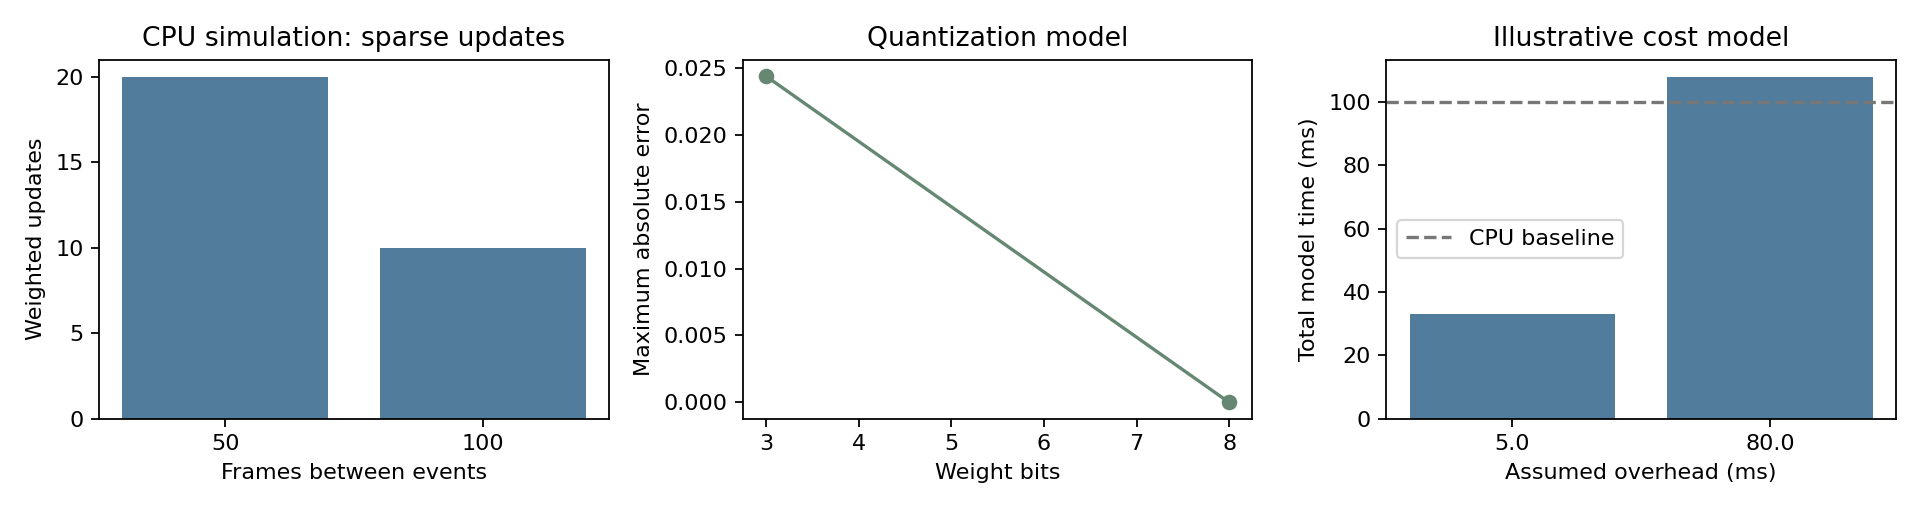

In [16]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("SKIPPED: optional Matplotlib unavailable; use the printed tables.")
else:
    if RESULTS is None:
        print("NOT RUN: collect results before plotting.")
    else:
        fig, axes = plt.subplots(1, 3, figsize=(12,3.2))
        if event_rows:
            axes[0].bar([str(int(r["period"])) for r in event_rows], [r["event_updates"] for r in event_rows], color="#517c9c")
        axes[0].set(title="CPU simulation: sparse updates", xlabel="Frames between events", ylabel="Weighted updates")
        if matrix_rows:
            axes[1].plot([r["bits"] for r in matrix_rows], [r["max_error"] for r in matrix_rows], marker="o", color="#668873")
        axes[1].set(title="Quantization model", xlabel="Weight bits", ylabel="Maximum absolute error")
        if hybrid_rows:
            axes[2].bar([str(r["overhead_ms"]) for r in hybrid_rows], [r["hybrid_ms"] for r in hybrid_rows], color="#517c9c")
            axes[2].axhline(100, color="#777777", linestyle="--", label="CPU baseline")
            axes[2].legend()
        axes[2].set(title="Illustrative cost model", xlabel="Assumed overhead (ms)", ylabel="Total model time (ms)")
        fig.tight_layout()
        fig.savefig(RUN/"concept_results.png", dpi=160)
        plt.show()


## 7 · Evidence, optional features and short handover
Optional OpenMP: set `openmp=True` and `CPUS=2`, rerun from Settings. It compares a two-thread C matrix calculation with the serial version. A missing OpenMP toolchain reports SKIPPED. A numerical mismatch reports FAIL. This four-row example measures no useful scaling result.

No quantum, neuromorphic, photonic or resistive hardware ran. MPI/GPU add no essential concept here and remain SKIPPED. This is deliberate resource discipline.

**Your short deliverable**
1. Save the completed notebook and `results.json`.
2. Choose one parameter, record your prediction, baseline and changed result.
3. Explain one numerical check and one reason that it could fail.
4. Identify which statements describe executed CPU calculations, counts or model assumptions.
5. Choose an architecture for a sparse sensor stream and another for a large accurate simulation. State what evidence you would need before deploying either.

**Four essentials:** workload fit, state/events, accuracy/measurement, complete hybrid cost.

**Bridge to Session 27:** what changes when a useful specialist must operate reliably inside a large, energy-constrained HPC installation?


In [17]:
if RESULTS:
    for name,item in RESULTS["optional"].items():
        print(name, item["status"], item.get("reason",item.get("evidence")))
    failed=[k for k,v in RESULTS["experiments"].items() if v["status"]=="FAIL"]
    print("Core failures:", failed or "none")
else:
    print("NOT RUN: no results collected yet.")
(RUN/"my_answers.json").write_text(json.dumps(answers, indent=2), encoding="utf-8")
print("Save your notebook and run folder:", RUN)


OpenMP NOT RUN Set openmp=True and provide two allocated CPUs to request this optional check.
GPU SKIPPED No hardware execution requested in this CPU concept lab.
MPI SKIPPED No hardware execution requested in this CPU concept lab.
QPU SKIPPED No hardware execution requested in this CPU concept lab.
NEUROMORPHIC SKIPPED No hardware execution requested in this CPU concept lab.
PHOTONIC SKIPPED No hardware execution requested in this CPU concept lab.
RESISTIVE_ARRAY SKIPPED No hardware execution requested in this CPU concept lab.
Core failures: none
Save your notebook and run folder: /workspace/scratch/203ecc1de7e8/notebook_validation/m6s1_lab/b56bebb2ee2c8195


## Reading and references
**Primary course plan:** Session 26, “Quantum, neuromorphic and alternative computing paradigms”. Main reading: Oscar Diez, *High Performance Computing: Applications and Frontiers*, Chapters 17–18. Supporting reading: *Foundations of High-Performance Computing*, Chapter 18 on emerging architectures. Session 27 covers exascale/post-exascale challenges.

**Repository conventions inspected:** root README, `cluster/README.md`, `cluster/COURSE_VALIDATION_NOTES.md`, M2S2 OpenMP, M3S1 performance/scalability, M3S2 memory/locality and M5S3 containers/reproducibility, plus `session_demos/11_scalability_patterns/`.

**Technical references**
- [IBM Quantum: superposition, phase and interference](https://quantum.cloud.ibm.com/learning/en/modules/quantum-mechanics/superposition-with-qiskit)
- [Intel: neuromorphic computing](https://www.intel.com/content/www/us/en/research/neuromorphic-computing.html)
- Feldmann et al., [In-memory computing on a photonic platform](https://pmc.ncbi.nlm.nih.gov/articles/PMC6377270/), primary device research. Our quantization experiment does not simulate that device.
- [Slurm sbatch](https://slurm.schedmd.com/sbatch.html) for scheduler options. Site configuration takes precedence.

**Published evidence:** saved outputs are LOCAL_CPU author validation. SciTech scheduler, compiler modules and compute-node execution still require actual validation. Do not relabel local results as cluster measurements.
